# Week 6 — Data Preprocessing for Machine Learning

**Internship phase:** Mathematics & Data Preprocessing  
**Assignment:** Convert raw data into a clean, machine-learning-ready dataset.

This notebook demonstrates missing-value handling, duplicate removal, outlier detection, label encoding, one-hot encoding, feature scaling, normalization and train/test splitting. The customer-churn dataset is synthetic and created for this assignment.

## 1. Learning objectives

By the end of this practical, we should be able to:
1. Inspect a raw dataset and identify quality problems.
2. Remove exact duplicate records and validate numeric ranges.
3. Detect possible outliers using the Interquartile Range (IQR).
4. Impute numeric and categorical missing values.
5. Encode categorical features and the target label.
6. Apply StandardScaler (standardization) and MinMaxScaler (normalization).
7. Split the data into training and testing sets without fitting preprocessing steps on the test data.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists():
    # Supports opening this notebook directly from the notebooks folder.
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))
from src.preprocessing import (NUMERIC_FEATURES, CATEGORICAL_FEATURES, FEATURE_COLUMNS,
                               remove_exact_duplicates, validate_domain_values,
                               iqr_outlier_summary, run_preprocessing)
print("Project root:", PROJECT_ROOT)
print("Pandas:", pd.__version__, "NumPy:", np.__version__)

Project root: /mnt/data/Week6_Data_Preprocessing
Pandas: 2.2.3 NumPy: 2.3.5


## 2. Load the raw dataset

`CustomerID` identifies records but is not a predictive feature. `Churn` is the target variable. The file intentionally includes missing values, exact duplicate rows and invalid numeric values so the cleaning techniques can be demonstrated.

In [2]:
raw = pd.read_csv(PROJECT_ROOT / "data/raw/customer_churn_raw.csv")
print("Shape:", raw.shape)
display(raw.head())
print("\nData types:")
print(raw.dtypes)
print("\nNumerical summary:")
display(raw.describe().T)

Shape: (508, 11)


,CustomerID,Age,TenureMonths,MonthlyCharges,TotalCharges,SupportCalls,ContractType,PaymentMethod,InternetService,PaperlessBilling,Churn
0,CUST0001,-5.0,31.0,25.15,716.90,2.0,Month-to-month,Credit card,No internet,Yes,No
1,CUST0002,145.0,19.0,95.04,1848.29,3.0,Month-to-month,Bank transfer,Fiber optic,Yes,No
2,CUST0003,31.0,150.0,101.02,7141.98,1.0,Month-to-month,Bank transfer,Fiber optic,No,Yes
3,CUST0004,49.0,68.0,999.00,3671.66,1.0,Month-to-month,Bank transfer,Fiber optic,Yes,No
4,CUST0005,56.0,42.0,79.48,-250.00,3.0,Month-to-month,Mailed check,Fiber optic,Yes,Yes



Data types:
CustomerID           object
Age                 float64
TenureMonths        float64
MonthlyCharges      float64
TotalCharges        float64
SupportCalls        float64
ContractType         object
PaymentMethod        object
InternetService      object
PaperlessBilling     object
Churn                object
dtype: object

Numerical summary:


,count,mean,std,min,25%,50%,75%,max
Age,488.0,42.165984,14.345084,-5.0,32.0000,42.00,51.0000,145.00
TenureMonths,496.0,34.991935,21.793242,0.0,16.0000,34.00,52.0000,150.00
MonthlyCharges,492.0,73.491789,52.923702,17.0,41.1275,74.13,96.4275,999.00
TotalCharges,491.0,2485.866273,2044.206818,-250.0,882.1600,1916.32,3685.8650,10020.87
SupportCalls,494.0,2.064777,2.816903,0.0,1.0000,2.00,3.0000,55.00


## 3. Missing-value analysis

`isna().sum()` counts missing cells in each column. The raw dataset is expected to have missing feature values. Numeric columns will later use the training median; categorical columns will use the training mode.

In [3]:
missing_summary = raw.isna().sum().sort_values(ascending=False)
display(missing_summary[missing_summary > 0].rename("missing_count").to_frame())
missing_summary.plot(kind="bar", figsize=(10,4), title="Missing values in raw data")
plt.ylabel("Missing cells"); plt.xticks(rotation=35); plt.tight_layout(); plt.show()

,missing_count
Age,20
TotalCharges,17
MonthlyCharges,16
SupportCalls,14
TenureMonths,12
ContractType,9
PaymentMethod,8
PaperlessBilling,7
InternetService,7


/tmp/ipykernel_2826/1258872281.py:4: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.ylabel("Missing cells"); plt.xticks(rotation=35); plt.tight_layout(); plt.show()


## 4. Duplicate removal

Exact duplicate rows can bias analysis and training. We remove only exact duplicate records. We do not delete customers merely because two different customers have similar feature values.

In [4]:
deduplicated, duplicate_report = remove_exact_duplicates(raw)
print(duplicate_report)
print("Unique customer IDs:", deduplicated["CustomerID"].nunique())
assert deduplicated["CustomerID"].is_unique

{'rows_before': 508, 'rows_after': 500, 'duplicates_removed': 8}
Unique customer IDs: 500


## 5. Domain validation and invalid values

IQR detects statistical extremes, but domain checks catch impossible values first. For example, negative age and a monthly bill of 999 are invalid under the documented data rules. We replace such values with `NaN` and later impute them using statistics learned from the training partition.

In [5]:
validated, domain_report = validate_domain_values(deduplicated)
print("Invalid values converted to missing by column:")
display(pd.Series(domain_report, name="invalid_values").to_frame())
print("\nMissing values after domain validation:")
display(validated.isna().sum().to_frame("missing_count"))

Invalid values converted to missing by column:


,invalid_values
Age,2
TenureMonths,1
MonthlyCharges,1
TotalCharges,1
SupportCalls,1



Missing values after domain validation:


,missing_count
CustomerID,0
Age,20
TenureMonths,13
MonthlyCharges,16
TotalCharges,18
SupportCalls,15
ContractType,9
PaymentMethod,8
InternetService,7
PaperlessBilling,6


## 6. Outlier detection using the IQR method

For a numeric feature, \(IQR = Q_3 - Q_1\). Values below \(Q_1 - 1.5(IQR)\) or above \(Q_3 + 1.5(IQR)\) are flagged for review. An outlier is not automatically an error; it may be a valid but unusual observation.

The table below is a descriptive audit. For the actual ML transformation, clipping bounds are fitted using **training data only**.

In [6]:
outlier_table = pd.DataFrame(iqr_outlier_summary(validated))
display(outlier_table)

,feature,q1,q3,lower_bound,upper_bound,outlier_count
0,Age,32.0000,51.0000,3.50000,79.50000,3
1,TenureMonths,16.0000,52.0000,-38.00000,106.00000,0
2,MonthlyCharges,40.6225,95.3100,-41.40875,177.34125,2
3,TotalCharges,887.0425,3696.1175,-3326.57000,7909.73000,8
4,SupportCalls,1.0000,3.0000,-2.00000,6.00000,5


## 7. Train/test split and preprocessing pipeline

We separate `Churn` from the input features and use a stratified 80/20 split. The identifier is excluded. Only after splitting do we fit imputers, IQR clipping thresholds, one-hot category vocabularies and scalers. This prevents test-set information from leaking into training.

In [7]:
result = run_preprocessing(PROJECT_ROOT, make_figures=True)
print("Duplicate report:", result["duplicate_report"])
print("Domain validation:", result["domain_report"])
print("Train shape:", result["X_train"].shape)
print("Test shape:", result["X_test"].shape)
print("Output variants:", result["outputs"])
print("Target mapping:", result["metadata"]["target_mapping"])

Duplicate report: {'rows_before': 508, 'rows_after': 500, 'duplicates_removed': 8}
Domain validation: {'Age': 2, 'TenureMonths': 1, 'MonthlyCharges': 1, 'TotalCharges': 1, 'SupportCalls': 1}
Train shape: (400, 9)
Test shape: (100, 9)
Output variants: {'standard': {'train_rows': 400, 'test_rows': 100, 'feature_count': 17, 'train_file': 'train_processed_standard.csv', 'test_file': 'test_processed_standard.csv'}, 'minmax': {'train_rows': 400, 'test_rows': 100, 'feature_count': 17, 'train_file': 'train_processed_minmax.csv', 'test_file': 'test_processed_minmax.csv'}}
Target mapping: {'No': 0, 'Yes': 1}


## 8. Label encoding and one-hot encoding

The target is mapped as `No → 0` and `Yes → 1`. Categorical input columns are one-hot encoded with `handle_unknown='ignore'`, so a previously unseen category in test or future data does not crash the transformer. Inspect the processed feature names below.

In [8]:
standard_train = pd.read_csv(PROJECT_ROOT / "data/processed/train_processed_standard.csv")
print("Encoded feature count:", standard_train.shape[1]-1)
print("First encoded columns:", standard_train.columns[:12].tolist())
display(standard_train.head())
print("Target counts (train):")
display(standard_train["Churn"].value_counts().rename(index={0:"No (0)",1:"Yes (1)"}).to_frame("count"))

Encoded feature count: 17
First encoded columns: ['numeric__Age', 'numeric__TenureMonths', 'numeric__MonthlyCharges', 'numeric__TotalCharges', 'numeric__SupportCalls', 'categorical__ContractType_Month-to-month', 'categorical__ContractType_One year', 'categorical__ContractType_Two year', 'categorical__PaymentMethod_Bank transfer', 'categorical__PaymentMethod_Credit card', 'categorical__PaymentMethod_Electronic check', 'categorical__PaymentMethod_Mailed check']


,numeric__Age,numeric__TenureMonths,numeric__MonthlyCharges,numeric__TotalCharges,numeric__SupportCalls,categorical__ContractType_Month-to-month,categorical__ContractType_One year,categorical__ContractType_Two year,categorical__PaymentMethod_Bank transfer,categorical__PaymentMethod_Credit card,categorical__PaymentMethod_Electronic check,categorical__PaymentMethod_Mailed check,categorical__InternetService_DSL,categorical__InternetService_Fiber optic,categorical__InternetService_No internet,categorical__PaperlessBilling_No,categorical__PaperlessBilling_Yes,Churn
0,-0.957272,1.188398,-0.364898,0.623407,0.911178,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0
1,0.308019,-0.013461,1.071680,1.543991,0.911178,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0
2,1.494229,0.419208,1.367618,1.323453,3.303768,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0
3,0.466181,-0.157684,0.074236,-0.815260,-0.683882,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0
4,-1.036352,1.092249,-1.111980,-0.219651,-0.683882,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0


Target counts (train):


,count
Churn,
No (0),314
Yes (1),86


## 9. Standardization versus normalization

- **Standardization:** `StandardScaler` transforms numeric training features to approximately zero mean and unit standard deviation. Test rows use the training means and standard deviations.
- **Normalization:** `MinMaxScaler` maps numeric training features to the [0, 1] interval. Test values can fall outside this interval if they are beyond the training range, although the training numeric columns should lie within it.

Both variants are saved so their behavior can be compared.

In [9]:
standard_numeric = [c for c in standard_train.columns if c.startswith("numeric__")]
minmax_train = pd.read_csv(PROJECT_ROOT / "data/processed/train_processed_minmax.csv")
minmax_numeric = [c for c in minmax_train.columns if c.startswith("numeric__")]
print("Standardized numeric means (near 0):")
display(standard_train[standard_numeric].mean().round(3).to_frame("mean"))
print("Min-max numeric ranges (approximately 0 to 1):")
display(pd.DataFrame({"min": minmax_train[minmax_numeric].min(), "max": minmax_train[minmax_numeric].max()}).round(3))

Standardized numeric means (near 0):


,mean
numeric__Age,0.0
numeric__TenureMonths,-0.0
numeric__MonthlyCharges,-0.0
numeric__TotalCharges,-0.0
numeric__SupportCalls,0.0


Min-max numeric ranges (approximately 0 to 1):


,min,max
numeric__Age,0.0,1.0
numeric__TenureMonths,0.0,1.0
numeric__MonthlyCharges,0.0,1.0
numeric__TotalCharges,0.0,1.0
numeric__SupportCalls,0.0,1.0


## 10. Train/test split verification

We verify row counts and class proportions. Stratification helps preserve the target distribution in both partitions. The test partition remains unseen during fitting of all preprocessing transformations.

In [10]:
split_check = pd.DataFrame({
    "partition": ["train", "test"],
    "rows": [len(standard_train), len(pd.read_csv(PROJECT_ROOT / "data/processed/test_processed_standard.csv"))],
    "churn_rate": [standard_train["Churn"].mean(), pd.read_csv(PROJECT_ROOT / "data/processed/test_processed_standard.csv")["Churn"].mean()]
})
display(split_check.round(3))
assert not standard_train.isna().any().any()
assert set(standard_train["Churn"].unique()).issubset({0,1})
print("No missing values remain in the processed training data.")

,partition,rows,churn_rate
0,train,400,0.215
1,test,100,0.210


No missing values remain in the processed training data.


## 11. Visual evidence

The script exports six figures under `outputs/figures/`: raw missingness, target distribution, numeric boxplots, numeric histograms, a correlation heatmap, and churn by contract type.

01_missing_values_raw.png


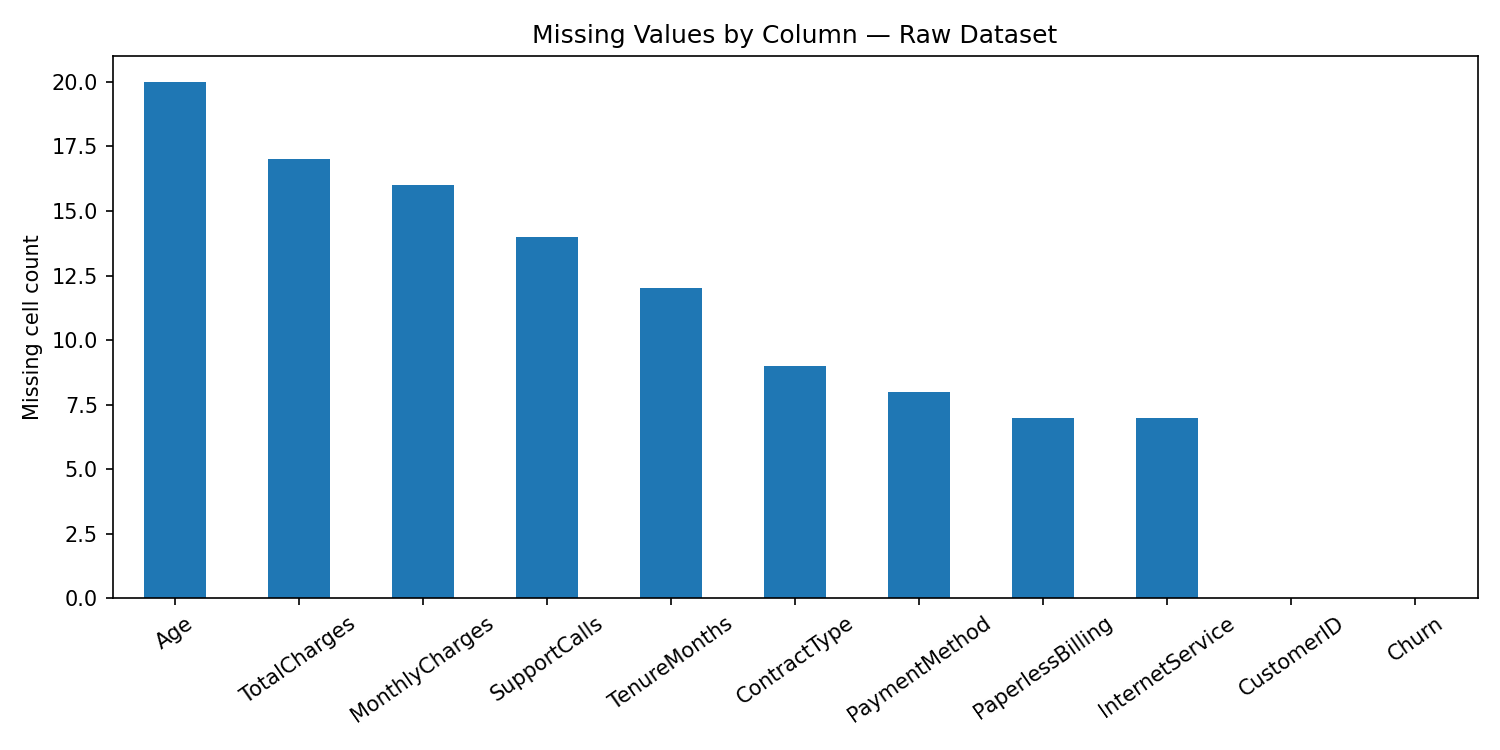

02_target_distribution.png


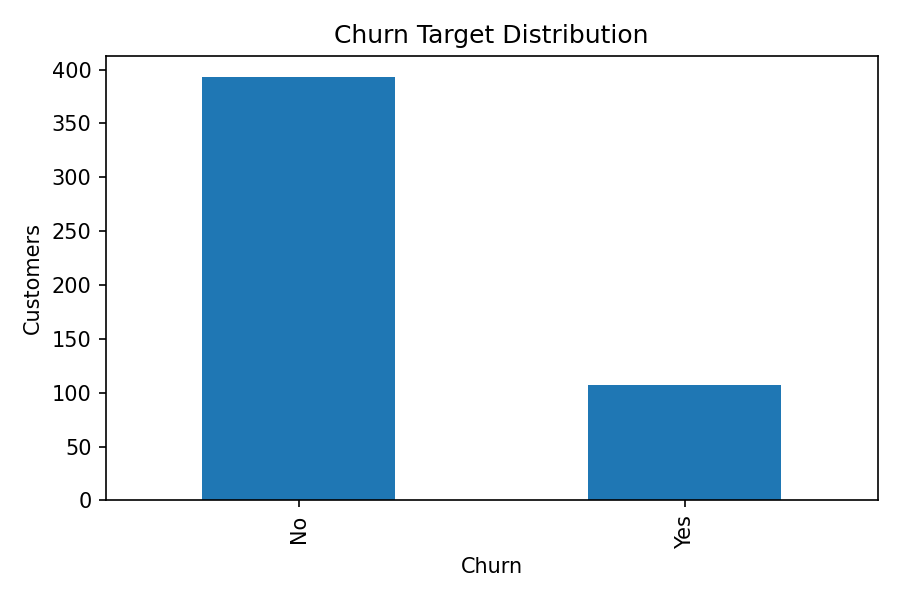

03_numeric_boxplots.png


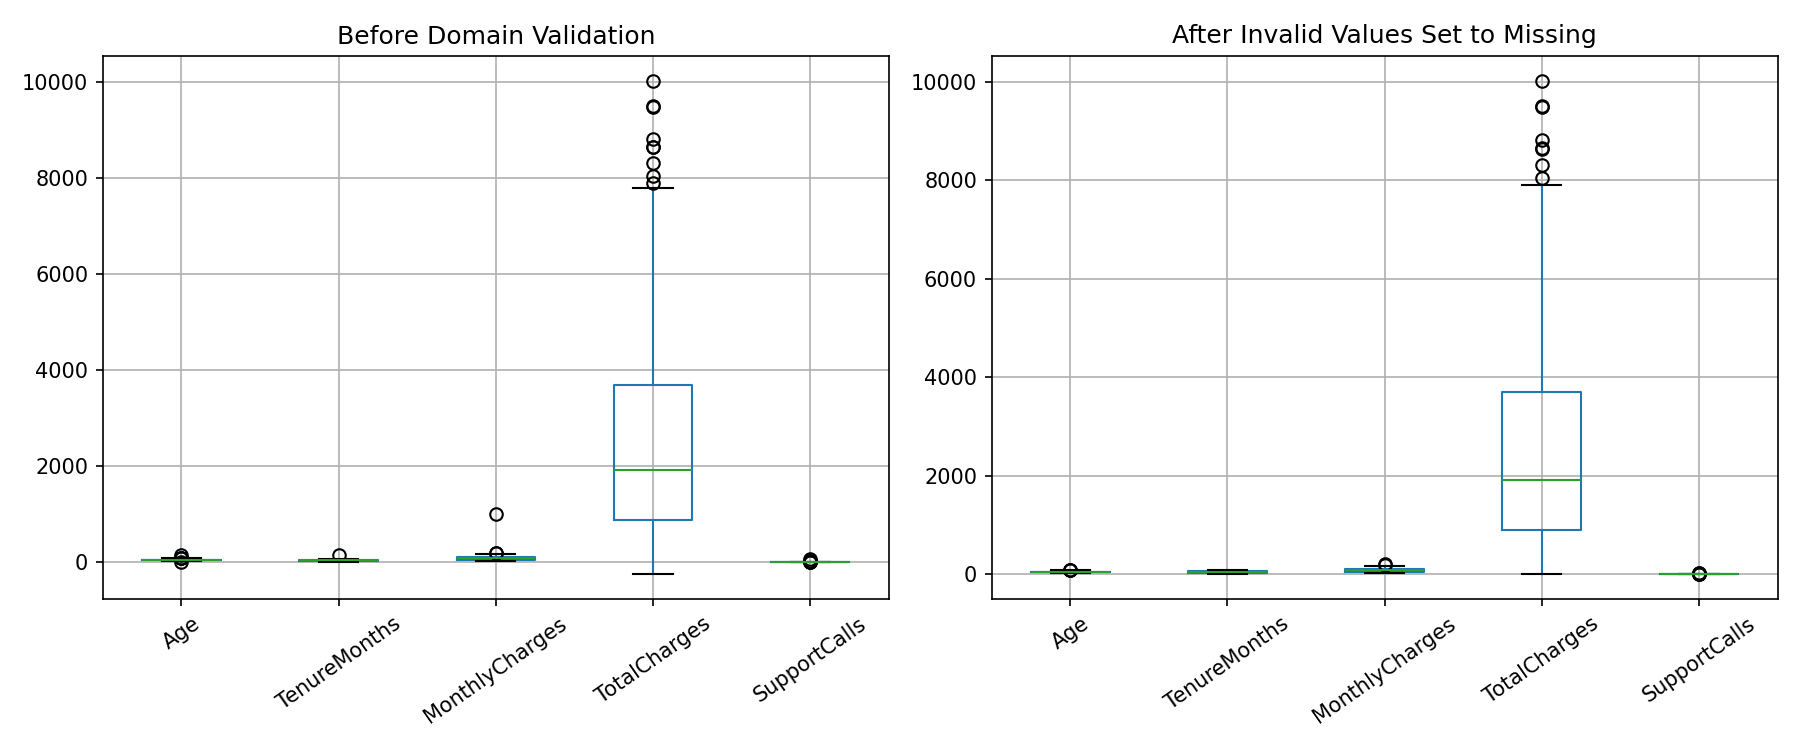

04_numeric_distributions.png


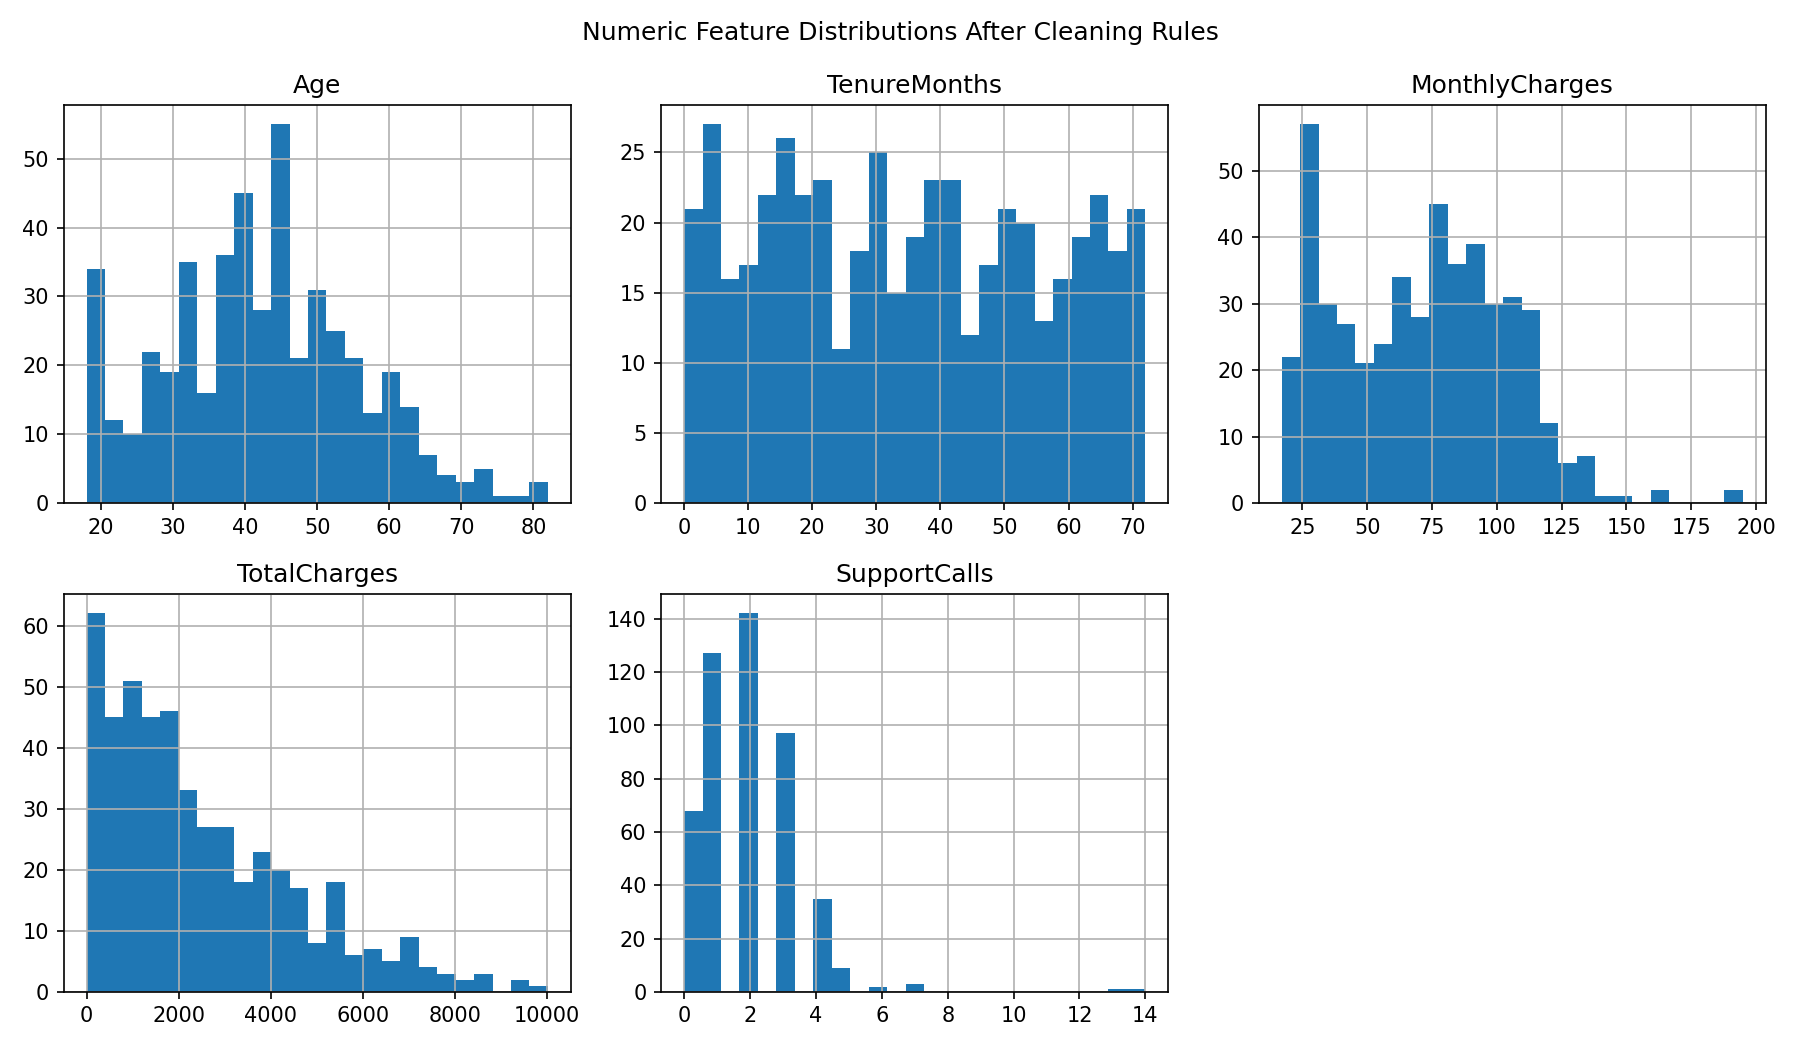

05_correlation_heatmap.png


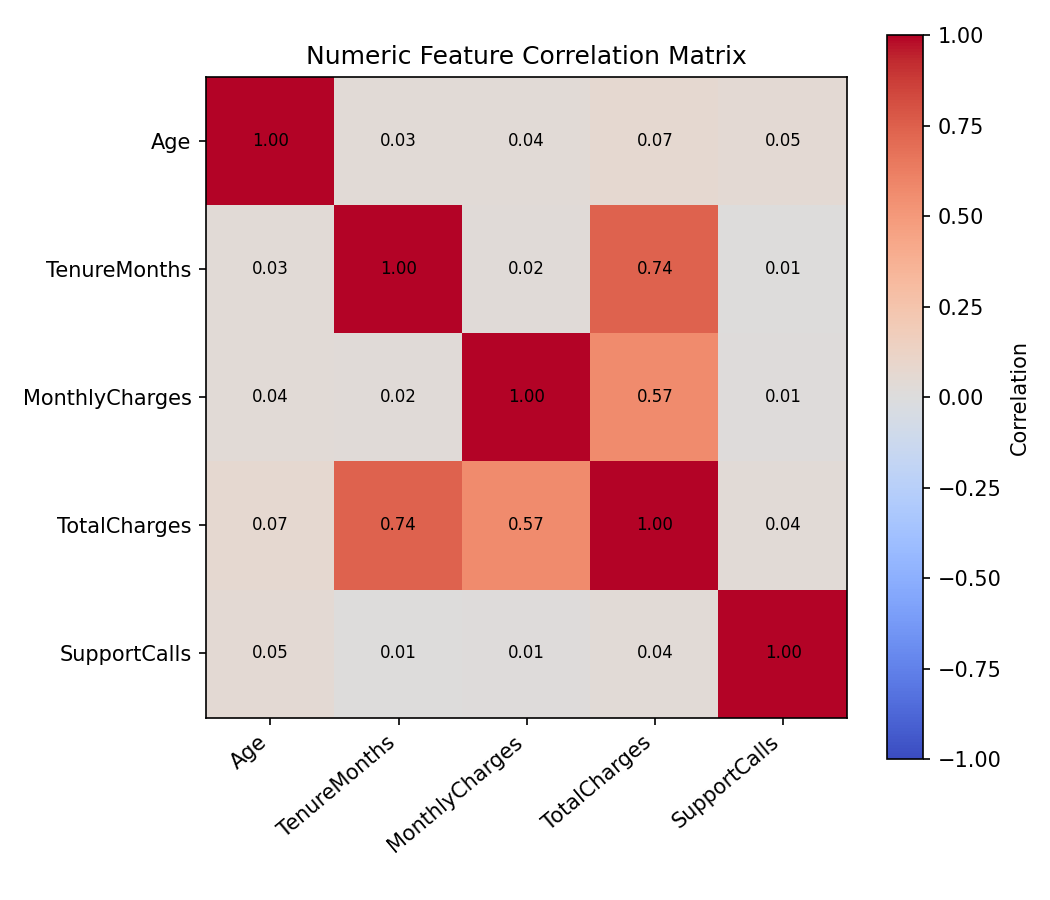

06_contract_churn.png


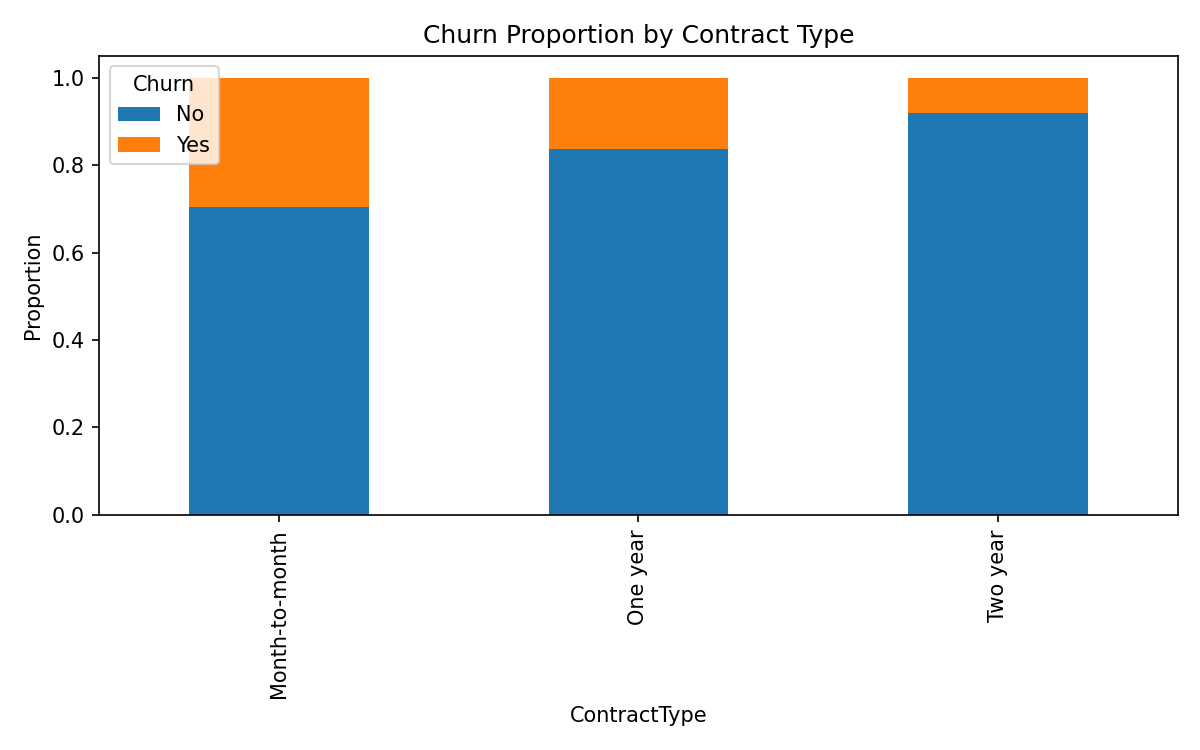

In [11]:
from IPython.display import Image, display as ipy_display
figure_dir = PROJECT_ROOT / "outputs/figures"
for image_name in ["01_missing_values_raw.png", "02_target_distribution.png", "03_numeric_boxplots.png",
                   "04_numeric_distributions.png", "05_correlation_heatmap.png", "06_contract_churn.png"]:
    print(image_name)
    ipy_display(Image(filename=str(figure_dir/image_name)))

## 12. Conclusions

The raw dataset has been profiled, exact duplicate rows removed and impossible numeric values changed to missing. Numeric and categorical missing values are imputed inside the train-fitted pipelines. Numeric outliers are reviewed and capped with IQR bounds learned on training data. Categorical variables are one-hot encoded, the target is label encoded, and two numeric transformation variants are exported: StandardScaler and MinMaxScaler. The final train/test split is stratified at 80/20.

**Important:** The generated data is synthetic. These outputs demonstrate the preprocessing workflow and should not be interpreted as real customer churn findings. No predictive model is trained in Week 6; model training begins in later internship weeks.